What is Image Enhancement?

Image enhancement means modifying an image so that important features become easier to see.

1. Log Transformation

s = c log(1+r)

r = input pixel intensity

s = output pixel intensity

c = constant

log = logarithm

Why use log transformation?

The logarithm has an interesting property:

Small intensity values get expanded

while

Large intensity values get compressed.




In [ ]:
from PIL import Image
import math


# ==========================================
# LOG TRANSFORMATION
# ==========================================

def log_transform(image):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Log transformation
            s = math.log(1 + r)

            # Normalize to 0-255
            s = (s / math.log(256)) * 255

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

result = log_transform(image)

result.save("log_output.png")

image.show()
result.show()

print("Log transformation completed.")
print("Output saved as log_output.png")

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg
Log transformation completed.
Output saved as log_output.png


2. Power-Law / Gamma Transformation

The formula is:

$$ s=cr^\gamma $$

Since:

$$ c=1 $$

we get:

$$ \boxed{s=r^\gamma} $$

where:

r = input pixel

s = output pixel

γ = gamma value

rn = r/255

Then apply gamma:

$$ s_n=r_n^\gamma $$

Then convert back:

$$ \boxed{s=255(r/255)^\gamma} $$

This is the practical formula we'll use.

What does Gamma do?

Gamma < 1  -> The image generally becomes brighter.

Gamma = 1 -> No change

Gamma > 1  -> The image generally becomes darker.

In [ ]:
from PIL import Image


# ==========================================
# POWER LAW / GAMMA TRANSFORMATION
# ==========================================

def gamma_transform(image, gamma):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Normalize pixel to 0-1
            normalized = r / 255.0

            # Gamma transformation
            s = normalized ** gamma

            # Convert back to 0-255
            s = s * 255

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

gamma = float(input("Enter gamma value: "))

result = gamma_transform(image, gamma)

result.save("gamma_output.png")

image.show()
result.show()

print("Gamma transformation completed.")
print("Output saved as gamma_output.png")

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg
Enter gamma value: 0.8
Gamma transformation completed.
Output saved as gamma_output.png


3. Intensity Level Transformation / Contrast Stretching


What is contrast stretching?

80 → 120

That means the image has relatively limited contrast.

We want to stretch it to:
50 → 150

so :

80 → 50

120 → 150

and values between them are mapped proportionally.


Input range:
r1 → r2

Output range:
s1 → s2

Then for an input pixel r:

$$ \boxed{ s=s_1+ \frac{(r-r_1)(s_2-s_1)} {(r_2-r_1)} } $$

This is basically the equation of a straight line



In [ ]:
from PIL import Image


# ==========================================
# CONTRAST STRETCHING
# ==========================================

def contrast_stretch(image, r1, r2, s1, s2):

    width, height = image.size

    result = Image.new("L", (width, height))

    for y in range(height):
        for x in range(width):

            r = image.getpixel((x, y))

            # Pixel below input range
            if r < r1:
                s = s1

            # Pixel above input range
            elif r > r2:
                s = s2

            # Pixel inside input range
            else:
                s = s1 + ((r - r1) * (s2 - s1)) / (r2 - r1)

            result.putpixel((x, y), int(s))

    return result


# ==========================================
# MAIN PROGRAM
# ==========================================

image_path = input("Enter image path: ")

image = Image.open(image_path)

# Convert to grayscale
image = image.convert("L")

# Input range
r1 = int(input("Enter input lower intensity: "))
r2 = int(input("Enter input upper intensity: "))

# Desired output range
s1 = int(input("Enter output lower intensity: "))
s2 = int(input("Enter output upper intensity: "))

result = contrast_stretch(
    image,
    r1,
    r2,
    s1,
    s2
)

result.save("contrast_output.png")

image.show()
result.show()

print("Contrast stretching completed.")
print("Output saved as contrast_output.png")

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg
Enter input lower intensity: 80
Enter input upper intensity: 150
Enter output lower intensity: 120
Enter output upper intensity: 200
Contrast stretching completed.
Output saved as contrast_output.png


In [ ]:
# NOW USING OPENCV

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg


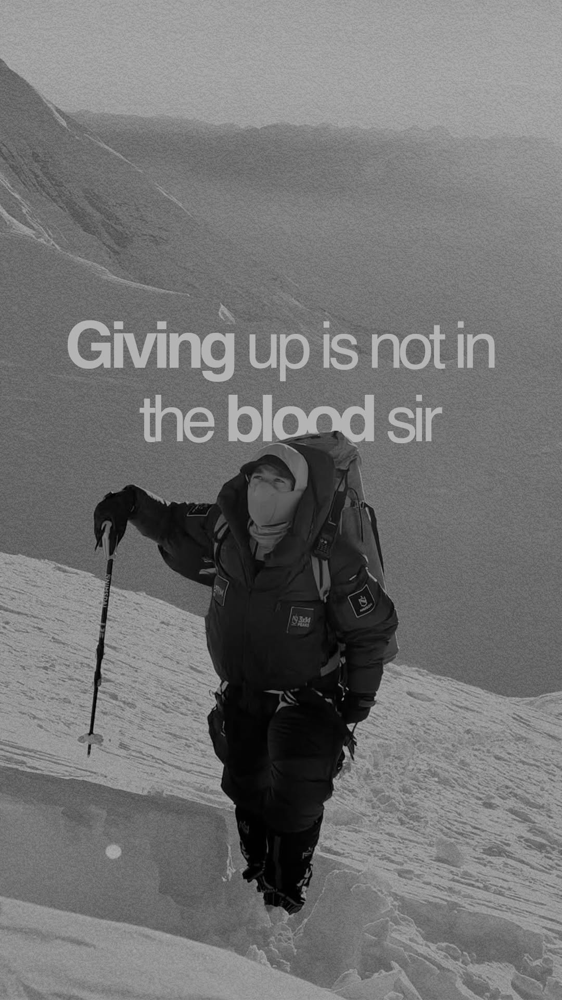

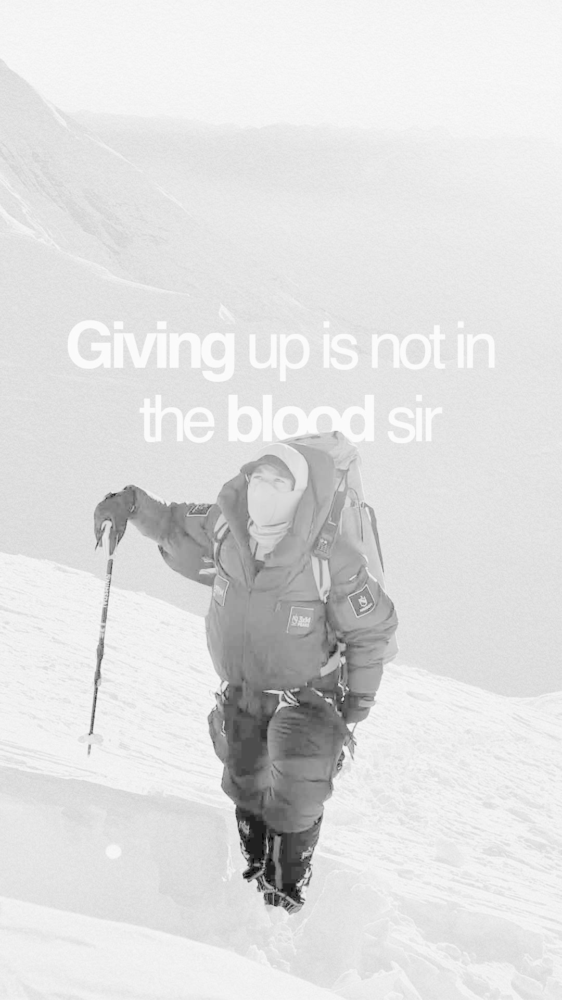

Log transformation completed.


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


# Convert pixels to float
image_float = image.astype(np.float32)

# Log transformation
result = np.log1p(image_float)

# Normalize to 0-255
result = cv2.normalize(
    result,
    None,
    0,
    255,
    cv2.NORM_MINMAX
)

result = result.astype(np.uint8)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_log_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Log transformation completed.")

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg
Enter gamma value: 0.5


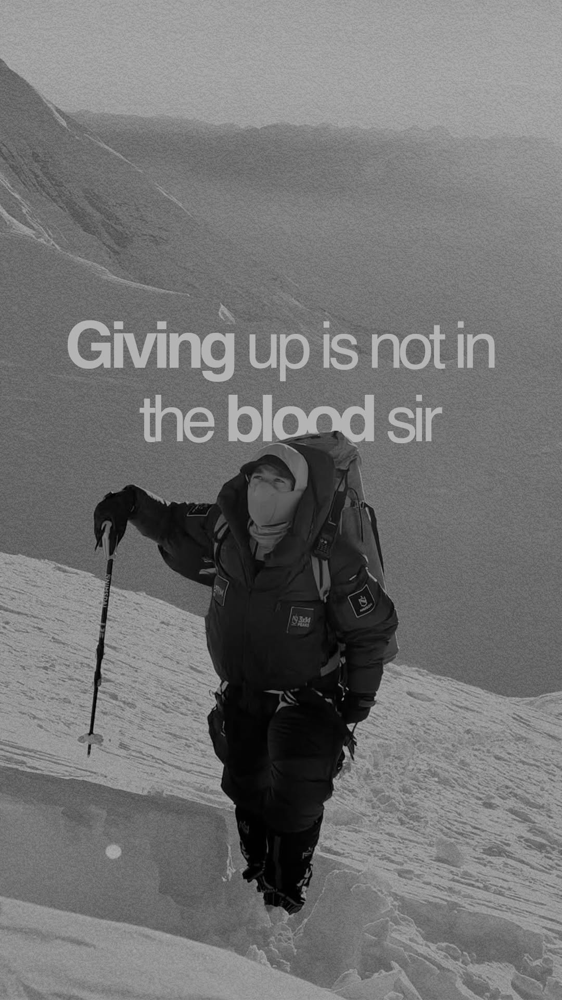

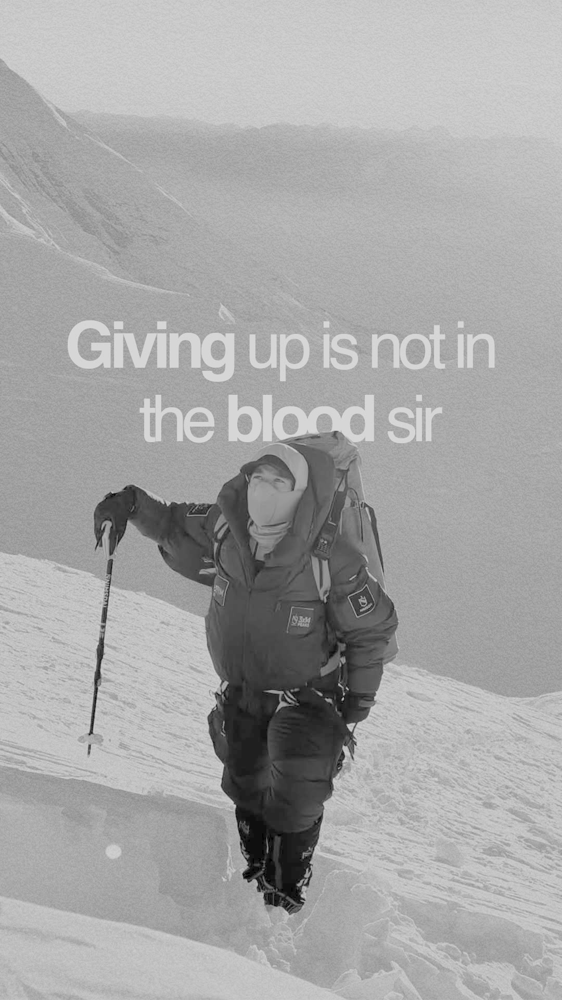

Gamma transformation completed.


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


gamma = float(input("Enter gamma value: "))


# Normalize image
normalized = image / 255.0

# Gamma transformation
result = np.power(normalized, gamma)

# Convert back to 0-255
result = result * 255

result = result.astype(np.uint8)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_gamma_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Gamma transformation completed.")

Enter image path: /content/d29c36e8ce74bb6bab478f9a126efde0-original-1080x1920-9x16.jpg
Enter input lower intensity: 50
Enter input upper intensity: 100
Enter output lower intensity: 100
Enter output upper intensity: 200


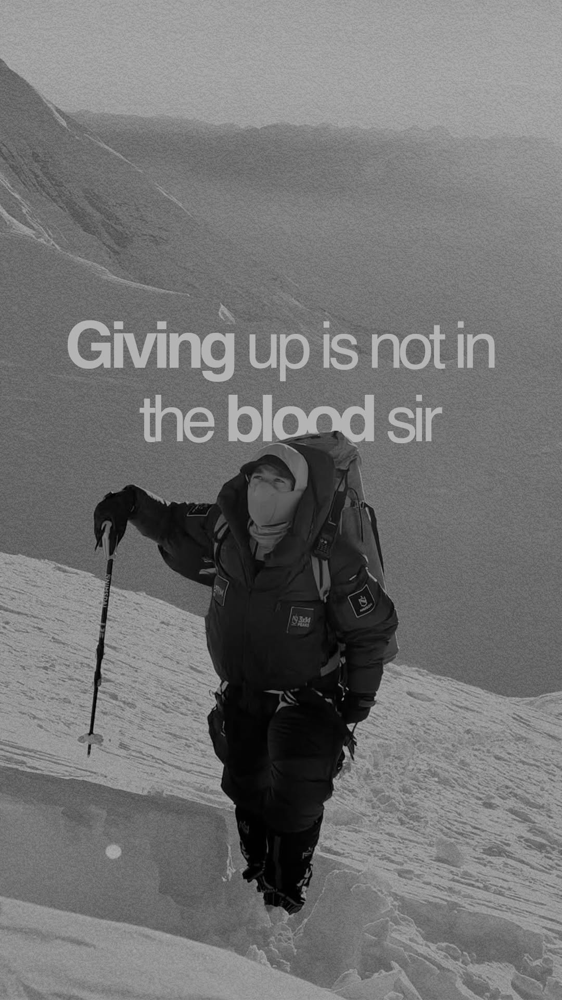

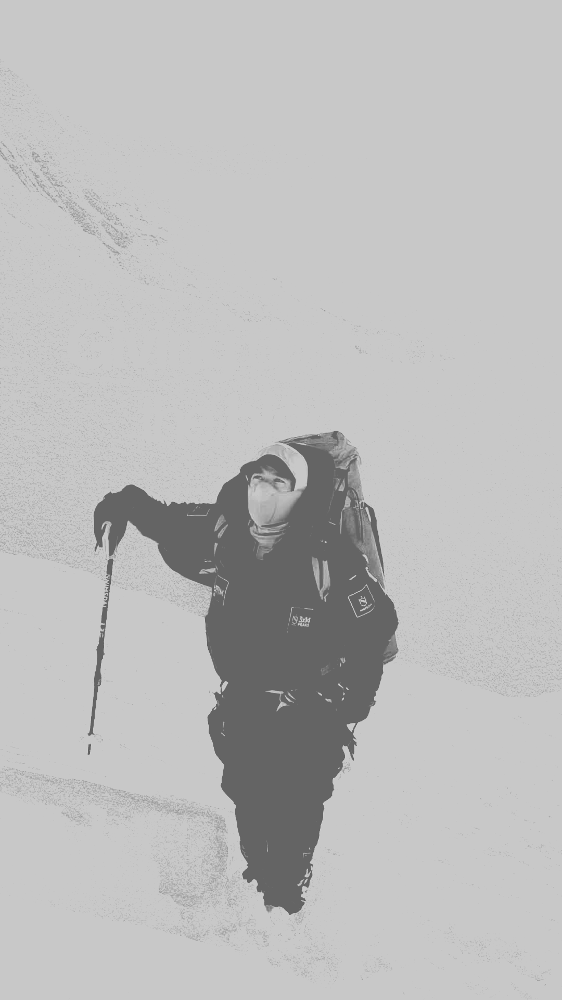

Contrast stretching completed.


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow


image_path = input("Enter image path: ")

image = cv2.imread(
    image_path,
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    print("Error: Image not found.")
    exit()


# Input range
r1 = int(input("Enter input lower intensity: "))
r2 = int(input("Enter input upper intensity: "))

# Output range
s1 = int(input("Enter output lower intensity: "))
s2 = int(input("Enter output upper intensity: "))


result = np.zeros_like(image)


for y in range(image.shape[0]):
    for x in range(image.shape[1]):

        r = int(image[y, x])

        if r < r1:
            s = s1

        elif r > r2:
            s = s2

        else:
            s = s1 + ((r - r1) * (s2 - s1)) / (r2 - r1)

        result[y, x] = int(s)


cv2_imshow(image)
cv2_imshow(result)

cv2.imwrite(
    "opencv_contrast_output.png",
    result
)

cv2.waitKey(0)
cv2.destroyAllWindows()

print("Contrast stretching completed.")